# 06. Avaliação Completa de Modelos

**DCT1401 — Inteligência Artificial (UFRN, 2026.2)**  
**Aluna:** Mariana dos Santos Batista Medeiros (Matrícula: 20230083988)

**Atividade 02 — Avaliação Comparativa de Modelos**

Este notebook realiza a avaliação comparativa do Sistema Especialista, da Árvore de Decisão, da Random Forest e do Gradient Boosting, conforme os requisitos da Seção 5.1 do enunciado.

Na classificação, são analisadas Accuracy, Precision, Recall, F1-score, ROC-AUC e Average Precision, além das matrizes de confusão e das curvas ROC e Precision–Recall.

Na regressão, são comparados os modelos de Árvore de Decisão, Random Forest e Gradient Boosting, utilizando métricas de erro, coeficiente de determinação e análise dos resíduos.

A avaliação considera as diferenças entre as métricas, o desbalanceamento das classes e as consequências dos erros de classificação e previsão.

São preservadas as seis variáveis preditoras, a divisão de 80% para treinamento e 20% para teste, a estratificação da classificação e a semente `random_state=42`.

Os seis modelos de aprendizado de máquina selecionados anteriormente são recuperados dos arquivos salvos, sem novos ajustes de hiperparâmetros. O Sistema Especialista é reconstruído a partir das 11 regras definidas no Notebook 03, sendo avaliado apenas na classificação.

O conjunto de teste permanece reservado para a avaliação final, permitindo comparar o desempenho dos modelos sem introduzir novas etapas de seleção.

**Configuração do ambiente — Google Colab**

Esta etapa conecta o Google Colab ao Google Drive e configura os caminhos necessários para acessar o dataset original e os módulos Python do projeto.

A execução pressupõe que a pasta `projeto-cardiovascular-ia-02` esteja localizada em `Meu Drive`, conforme as instruções disponíveis no `README.md` da Atividade 02.

O código verifica a existência do dataset e prepara o ambiente para a execução das etapas seguintes.

In [ ]:
from google.colab import drive
from pathlib import Path
import os
import sys

drive.mount("/content/drive")

PROJETO = Path(
    "/content/drive/MyDrive/projeto-cardiovascular-ia-02"
)

os.chdir(PROJETO / "notebooks")

if str(PROJETO) not in sys.path:
    sys.path.insert(0, str(PROJETO))

arquivos_necessarios = [
    "data/raw/cardiovascular_disease_prediction.csv",
    "src/pipeline_data.py",
    "src/metrics.py",
    "src/expert_system.py",
    "rules/regras_classificacao.txt",
    "models/decision_tree_clf.joblib",
    "models/decision_tree_reg.joblib",
    "models/random_forest_clf.joblib",
    "models/random_forest_reg.joblib",
    "models/gradient_boosting_clf.joblib",
    "models/gradient_boosting_reg.joblib"
]

for arquivo in arquivos_necessarios:
    caminho = PROJETO / arquivo
    assert caminho.is_file(), f"Arquivo não encontrado: {arquivo}"
    print(f"OK: {arquivo}")

print("\nAmbiente do Notebook 06 verificado com sucesso!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
OK: data/raw/cardiovascular_disease_prediction.csv
OK: src/pipeline_data.py
OK: src/metrics.py
OK: src/expert_system.py
OK: rules/regras_classificacao.txt
OK: models/decision_tree_clf.joblib
OK: models/decision_tree_reg.joblib
OK: models/random_forest_clf.joblib
OK: models/random_forest_reg.joblib
OK: models/gradient_boosting_clf.joblib
OK: models/gradient_boosting_reg.joblib

Ambiente do Notebook 06 verificado com sucesso!


## 1. Recuperação dos dados e modelos treinados

A comparação utiliza a mesma divisão dos dados adotada nos Notebooks 03, 04 e 05, com 16.000 registros de treinamento e 4.000 de teste.

Os seis Pipelines de aprendizado de máquina são carregados dos arquivos já salvos, preservando o pré-processamento e os hiperparâmetros selecionados anteriormente. Nenhum modelo será retreinado nesta etapa.

In [ ]:
import importlib
import joblib
import numpy as np
import pandas as pd

import src.pipeline_data as pipeline_data
import src.metrics as metricas

importlib.reload(pipeline_data)
importlib.reload(metricas)

# Recuperar exatamente a mesma divisão
(
    X_train,
    X_test,
    y_train_c,
    y_test_c,
    y_train_r,
    y_test_r,
    feat_cols
) = pipeline_data.carregar_e_dividir_dados_sem_leakage(
    "../data/raw/cardiovascular_disease_prediction.csv"
)

# Recuperar os modelos já treinados
modelos_classificacao = {
    "Árvore de Decisão": joblib.load(
        PROJETO / "models/decision_tree_clf.joblib"
    ),
    "Random Forest": joblib.load(
        PROJETO / "models/random_forest_clf.joblib"
    ),
    "Gradient Boosting": joblib.load(
        PROJETO / "models/gradient_boosting_clf.joblib"
    )
}

modelos_regressao = {
    "Árvore de Decisão": joblib.load(
        PROJETO / "models/decision_tree_reg.joblib"
    ),
    "Random Forest": joblib.load(
        PROJETO / "models/random_forest_reg.joblib"
    ),
    "Gradient Boosting": joblib.load(
        PROJETO / "models/gradient_boosting_reg.joblib"
    )
}

# Verificações de consistência
assert X_train.shape == (16000, 6)
assert X_test.shape == (4000, 6)
assert X_train.index.intersection(X_test.index).empty

for modelo in (
    list(modelos_classificacao.values())
    + list(modelos_regressao.values())
):
    assert list(
        modelo.feature_names_in_
    ) == feat_cols

print("Treinamento:", X_train.shape)
print("Teste:", X_test.shape)
print("Modelos de classificação:", len(modelos_classificacao))
print("Modelos de regressão:", len(modelos_regressao))
print("\nDados e seis Pipelines recuperados com sucesso!")

Treinamento: (16000, 6)
Teste: (4000, 6)
Modelos de classificação: 3
Modelos de regressão: 3

Dados e seis Pipelines recuperados com sucesso!


## 2. Recuperação do Sistema Especialista

O Sistema Especialista é reconstruído a partir das 11 regras previamente definidas, respeitando sua ordem de prioridade e o mecanismo de fallback do Notebook 03.

Para cada regra, o escore corresponde à proporção de registros positivos observada no treinamento entre aqueles cuja decisão foi efetivamente atribuída àquela regra. O fallback utiliza a proporção de positivos entre os registros de treinamento não classificados por nenhuma regra.

Dessa forma, cada registro recebe a classificação determinada pela primeira regra aplicável, ou pelo fallback, acompanhada de um escore empírico. Neste experimento, são produzidos 12 valores distintos de escore, fazendo com que as curvas ROC e Precision-Recall do Sistema Especialista apresentem degraus mais evidentes.

Esses escores permitem avaliar a capacidade de discriminação do sistema, mas não devem ser interpretados como probabilidades clínicas calibradas.

Todos os escores são calculados exclusivamente a partir do treinamento. O conjunto de teste é utilizado somente para avaliação.

In [ ]:
import src.expert_system as modulo_se

importlib.reload(modulo_se)

from src.expert_system import (
    BaseConhecimentoClassificacao,
    MotorInferenciaClassificacao
)

# Mesmo pré-processamento do Notebook 03
X_train_se, X_test_se, preprocessador_se = (
    pipeline_data.preparar_dados_sistema_especialista(
        X_train, X_test
    )
)

# Recuperar a mesma base de conhecimento
base = BaseConhecimentoClassificacao(
    "../rules/regras_classificacao.txt"
)

# Calcular os escores somente no treinamento
base.analisar_no_treinamento(
    X_train_se,
    y_train_c
)

motor = MotorInferenciaClassificacao(base)

# Inferência no conjunto de teste
pred_se, esc_se, regras_se = motor.inferir(
    X_test_se
)

# Verificar a consistência com o Notebook 03
assert len(base.regras) == 11
assert len(pred_se) == 4000
assert np.isfinite(esc_se).all()

metricas_se = metricas.calcular_metricas_classificacao(
    y_test_c,
    pred_se,
    esc_se
)

print("SISTEMA ESPECIALISTA RECUPERADO")
print("Regras:", len(base.regras))
print("Fallback no teste:", np.sum(regras_se == "FALLBACK"))
print(f"Acurácia: {metricas_se['Accuracy']:.4f}")
print(f"Recall: {metricas_se['Recall']:.4f}")
print(f"F1-score: {metricas_se['F1-score']:.4f}")
print(f"ROC-AUC: {metricas_se['ROC-AUC']:.4f}")
print(f"PR-AUC: {metricas_se['PR-AUC']:.4f}")
print(
    f"Average Precision: "
    f"{metricas_se['Average_Precision']:.4f}"
)

SISTEMA ESPECIALISTA RECUPERADO
Regras: 11
Fallback no teste: 748
Acurácia: 0.7728
Recall: 0.6119
F1-score: 0.6224
ROC-AUC: 0.7909
PR-AUC: 0.6597
Average Precision: 0.6213


## 3. Comparação das métricas de classificação

Os quatro classificadores são avaliados nos mesmos 4.000 registros de teste, utilizando Accuracy, Precision, Recall, F1-score, ROC-AUC, PR-AUC e Average Precision.

**O F1-score foi definido como métrica principal de classificação**, mantendo coerência com a seleção de hiperparâmetros realizada por validação cruzada. Essa métrica combina precisão e recall, permitindo avaliar o equilíbrio entre falsos positivos e falsos negativos.

O Recall é utilizado como métrica complementar, especialmente importante em um cenário hipotético de triagem, no qual deixar de identificar um registro positivo pode representar um custo maior que produzir um falso positivo. Essa consideração não estabelece validade clínica para os modelos.

A classe positiva representa 30,6% do conjunto de teste. Como 2.776 dos 4.000 registros pertencem à classe negativa, um classificador que sempre previsse a classe 0 alcançaria acurácia de 69,4%, mesmo sem identificar qualquer registro positivo.

As acurácias dos modelos avaliados, entre 77,28% e 78,65%, superam essa referência por aproximadamente 8 a 9 pontos percentuais. Portanto, a acurácia isoladamente não é suficiente para avaliar o desempenho, sendo necessário considerar F1-score, Recall e Average Precision.

O Sistema Especialista utiliza escores empíricos obtidos exclusivamente no treinamento, enquanto os modelos de aprendizado de máquina utilizam escores probabilísticos estimados. As métricas ROC-AUC, PR-AUC e Average Precision avaliam a discriminação ao longo de diferentes limiares, enquanto Precision, Recall e F1-score consideram as classificações efetivamente produzidas.

In [ ]:
# Reunir previsões e escores dos quatro classificadores

y_real = np.asarray(y_test_c).ravel()

previsoes_classificacao = {
    "Sistema Especialista": np.asarray(pred_se).ravel()
}

scores_classificacao = {
    "Sistema Especialista": np.asarray(esc_se).ravel()
}

for nome, pipeline in modelos_classificacao.items():

    assert np.array_equal(
        pipeline.classes_, [0, 1]
    ), f"Ordem inesperada das classes em {nome}"

    previsoes_classificacao[nome] = pipeline.predict(
        X_test
    )

    scores_classificacao[nome] = pipeline.predict_proba(
        X_test
    )[:, 1]

# Calcular todas as métricas a partir das previsões atuais
registros_classificacao = []
matrizes_classificacao = {}

for nome in previsoes_classificacao:

    resultado = metricas.calcular_metricas_classificacao(
        y_real,
        previsoes_classificacao[nome],
        scores_classificacao[nome]
    )

    matrizes_classificacao[nome] = resultado[
        "Confusion_Matrix"
    ]

    registros_classificacao.append({
        "Modelo": nome,
        **{
            chave: valor
            for chave, valor in resultado.items()
            if chave != "Confusion_Matrix"
        }
    })

tabela_comparacao_c = pd.DataFrame(
    registros_classificacao
)

# Criar pasta e salvar a tabela
pasta_tabelas = PROJETO / "reports" / "tables"
pasta_tabelas.mkdir(parents=True, exist_ok=True)

tabela_comparacao_c.to_csv(
    pasta_tabelas / "comparacao_classificacao.csv",
    index=False,
    float_format="%.16g"
)

# Verificações de consistência
assert len(y_real) == 4000
assert len(tabela_comparacao_c) == 4

for nome in scores_classificacao:
    assert len(scores_classificacao[nome]) == 4000
    assert np.isfinite(scores_classificacao[nome]).all()

print("COMPARAÇÃO FINAL — CLASSIFICAÇÃO")
print(f"Registros avaliados: {len(y_real)}")
print(f"Classe positiva: {np.mean(y_real):.2%}")

display(tabela_comparacao_c.round(4))

COMPARAÇÃO FINAL — CLASSIFICAÇÃO
Registros avaliados: 4000
Classe positiva: 30.60%


,Modelo,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC,Average_Precision
0,Sistema Especialista,0.7728,0.6331,0.6119,0.6224,0.7909,0.6597,0.6213
1,Árvore de Decisão,0.7795,0.6583,0.5809,0.6172,0.7842,0.6562,0.6121
2,Random Forest,0.7845,0.6874,0.5425,0.6064,0.8006,0.6925,0.6921
3,Gradient Boosting,0.7865,0.6884,0.5523,0.6129,0.8009,0.6947,0.6935


## 4. Curvas ROC e Precision-Recall

As curvas ROC e Precision-Recall permitem comparar a capacidade dos quatro classificadores de distinguir as classes em diferentes limiares de decisão.

A curva ROC relaciona a taxa de verdadeiros positivos à taxa de falsos positivos. A curva Precision-Recall apresenta a relação entre precisão e sensibilidade, sendo especialmente útil quando a classe positiva é minoritária.

Na curva Precision-Recall, a legenda apresenta Average Precision (AP). Essa métrica é relacionada à PR-AUC trapezoidal, mas não é matematicamente idêntica a ela. Ambas estão registradas na tabela comparativa.

Os escores do Sistema Especialista são frequências empíricas e não probabilidades calibradas.

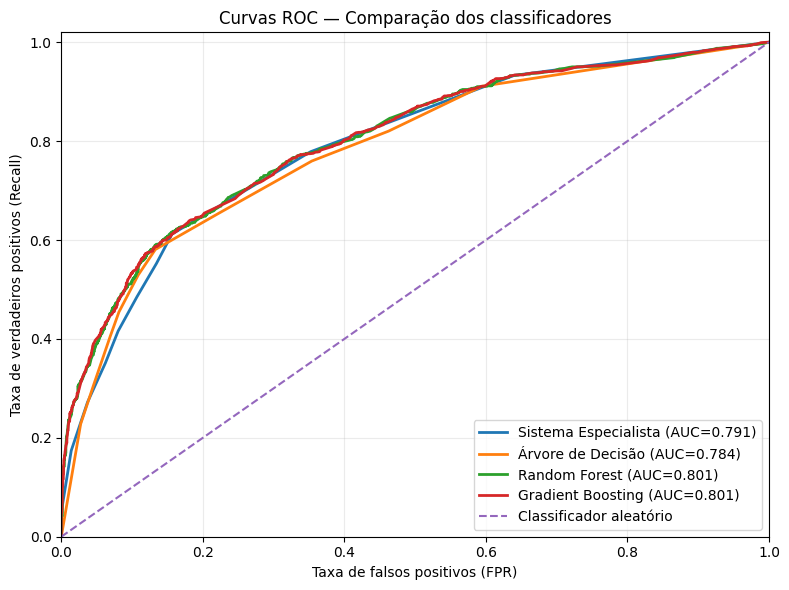

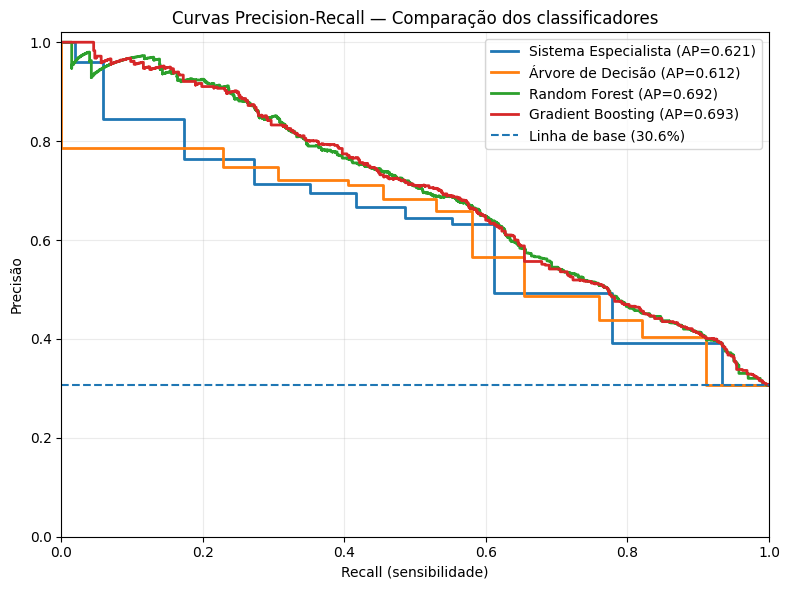

Curvas ROC e Precision-Recall geradas e salvas!


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    roc_auc_score,
    average_precision_score
)

pasta_figuras = PROJETO / "reports" / "figures"
pasta_figuras.mkdir(parents=True, exist_ok=True)

# -------- CURVA ROC --------

fig, ax = plt.subplots(figsize=(8, 6))

for nome, scores in scores_classificacao.items():

    fpr, tpr, _ = roc_curve(
        y_real, scores
    )

    area_roc = roc_auc_score(
        y_real, scores
    )

    ax.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{nome} (AUC={area_roc:.3f})"
    )

ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Classificador aleatório"
)

ax.set_title("Curvas ROC — Comparação dos classificadores")
ax.set_xlabel("Taxa de falsos positivos (FPR)")
ax.set_ylabel("Taxa de verdadeiros positivos (Recall)")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.legend(loc="lower right")
ax.grid(alpha=0.25)

fig.tight_layout()

fig.savefig(
    pasta_figuras / "comparacao_roc_validada.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# -------- CURVA PRECISION-RECALL --------

fig, ax = plt.subplots(figsize=(8, 6))

for nome, scores in scores_classificacao.items():

    precisao, recall, _ = precision_recall_curve(
        y_real, scores
    )

    ap = average_precision_score(
        y_real, scores
    )

    # Ordenar o recall de forma crescente
    recall_crescente = recall[::-1]
    precisao_crescente = precisao[::-1]

    # Verificar a área representada pelos degraus
    ap_degraus = np.sum(
        np.diff(recall_crescente)
        * precisao_crescente[1:]
    )

    assert np.isclose(
        ap_degraus, ap, atol=1e-12
    ), f"Inconsistência na curva PR de {nome}"

    # Representar corretamente os degraus da curva
    ax.step(
        recall_crescente,
        precisao_crescente,
        where="pre",
        linewidth=2,
        label=f"{nome} (AP={ap:.3f})"
    )

prevalencia = np.mean(y_real)

ax.axhline(
    prevalencia,
    linestyle="--",
    label=f"Linha de base ({prevalencia:.1%})"
)

ax.set_title(
    "Curvas Precision-Recall — Comparação dos classificadores"
)
ax.set_xlabel("Recall (sensibilidade)")
ax.set_ylabel("Precisão")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.legend(loc="best")
ax.grid(alpha=0.25)

fig.tight_layout()

fig.savefig(
    pasta_figuras / "comparacao_pr_validada.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Curvas ROC e Precision-Recall geradas e salvas!")

### 4.1 Interpretação das curvas ROC e Precision-Recall

As curvas ROC mostram que os quatro classificadores apresentam capacidade de discriminação superior à classificação aleatória. Random Forest e Gradient Boosting obtiveram os maiores valores de ROC-AUC, aproximadamente 0,801, seguidos pelo Sistema Especialista (0,7909) e pela Árvore de Decisão (0,7842).

Na análise Precision-Recall, os ensembles apresentaram maior Average Precision, com 0,6921 para a Random Forest e 0,6935 para o Gradient Boosting, enquanto o Sistema Especialista alcançou 0,6213 e a Árvore de Decisão, 0,6121. Esses resultados indicam melhor capacidade dos ensembles de ordenar os registros positivos ao considerar diferentes limiares de decisão.

Entretanto, o Sistema Especialista apresentou o maior F1-score (0,6224) e recall (0,6119) nas classificações efetivamente produzidas. Isso demonstra que um modelo com melhor desempenho na ordenação dos casos não necessariamente apresenta o melhor F1-score no limiar de decisão utilizado.

A classe positiva representa 30,6% do conjunto de teste, tornando importante analisar a curva Precision-Recall juntamente com a ROC. As diferenças entre Random Forest e Gradient Boosting foram pequenas, não permitindo concluir superioridade estatística de um sobre o outro.

Os escores empíricos do Sistema Especialista não representam probabilidades calibradas. As curvas foram utilizadas exclusivamente para avaliação, sem modificar os limiares ou reajustar os modelos.

## 5. Comparação das matrizes de confusão

As matrizes de confusão apresentam os resultados dos quatro classificadores sobre os mesmos 4.000 registros de teste.

São analisados os verdadeiros negativos (VN), falsos positivos (FP), falsos negativos (FN) e verdadeiros positivos (VP), permitindo identificar diferenças entre os tipos de erro.

A comparação é especialmente relevante porque os falsos negativos representam registros cuja classe verdadeira é positiva, mas que foram classificados como negativos. Os resultados são interpretados no contexto do conjunto de dados, sem atribuir validade clínica aos modelos.

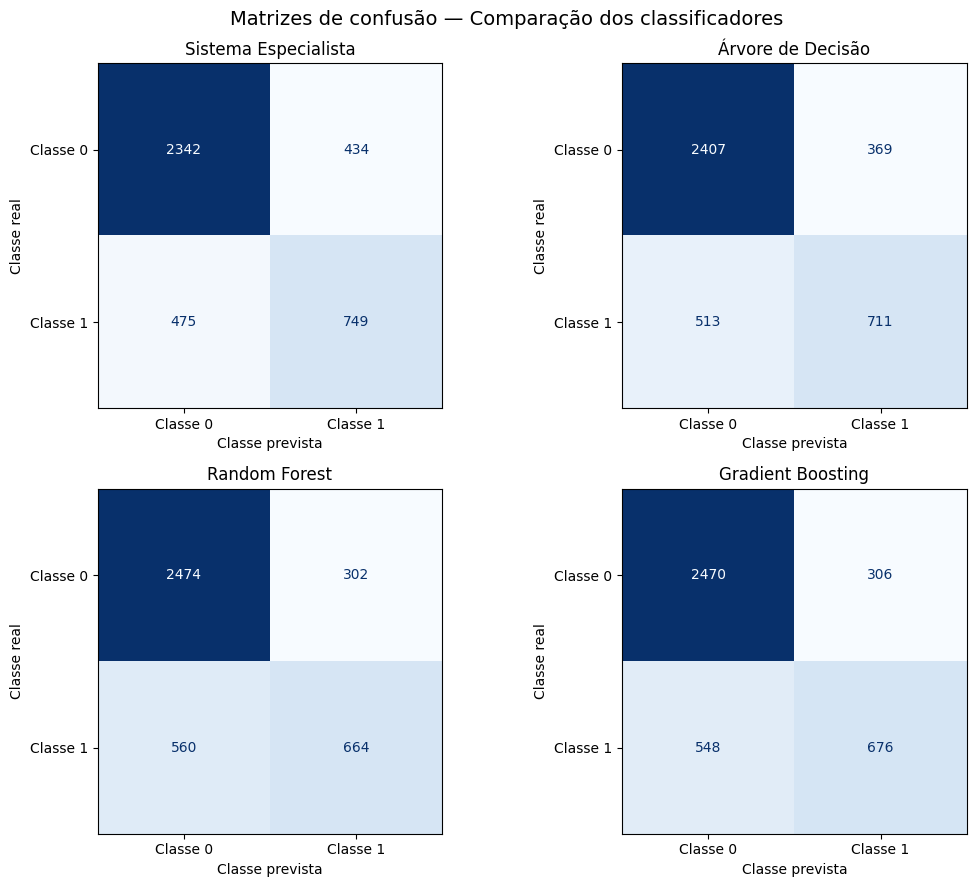

COMPARAÇÃO DAS MATRIZES DE CONFUSÃO


,Modelo,VN,FP,FN,VP,Total,Taxa falsos negativos,Taxa falsos positivos
0,Sistema Especialista,2342,434,475,749,4000,0.3881,0.1563
1,Árvore de Decisão,2407,369,513,711,4000,0.4191,0.1329
2,Random Forest,2474,302,560,664,4000,0.4575,0.1088
3,Gradient Boosting,2470,306,548,676,4000,0.4477,0.1102



Figura e tabela salvas com sucesso!


In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Matrizes calculadas anteriormente com os modelos validados
assert len(matrizes_classificacao) == 4

fig, axes = plt.subplots(2, 2, figsize=(11, 9))

registros_matrizes = []

for ax, (nome, matriz) in zip(
    axes.ravel(),
    matrizes_classificacao.items()
):
    matriz = np.asarray(matriz)

    assert matriz.shape == (2, 2)
    assert matriz.sum() == 4000

    vn, fp, fn, vp = matriz.ravel()

    # Visualização da matriz
    visualizacao = ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=["Classe 0", "Classe 1"]
    )

    visualizacao.plot(
        ax=ax,
        values_format="d",
        cmap="Blues",
        colorbar=False
    )

    # Padronizar os eixos em português
    ax.set_xlabel("Classe prevista")
    ax.set_ylabel("Classe real")
    ax.set_title(nome)

    # Registrar os resultados numéricos
    registros_matrizes.append({
        "Modelo": nome,
        "VN": int(vn),
        "FP": int(fp),
        "FN": int(fn),
        "VP": int(vp),
        "Total": int(matriz.sum()),
        "Taxa falsos negativos": fn / (fn + vp),
        "Taxa falsos positivos": fp / (fp + vn)
    })

fig.suptitle(
    "Matrizes de confusão — Comparação dos classificadores",
    fontsize=14
)

fig.tight_layout()

# Salvar a figura
fig.savefig(
    pasta_figuras / "comparacao_matrizes_confusao_validada.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# Tabela comparativa
tabela_matrizes = pd.DataFrame(registros_matrizes)

# Verificar que todos utilizaram as mesmas classes reais
assert (
    tabela_matrizes["VN"] + tabela_matrizes["FP"] == 2776
).all()

assert (
    tabela_matrizes["FN"] + tabela_matrizes["VP"] == 1224
).all()

tabela_matrizes.to_csv(
    pasta_tabelas / "comparacao_matrizes_confusao.csv",
    index=False
)

print("COMPARAÇÃO DAS MATRIZES DE CONFUSÃO")
display(tabela_matrizes.round(4))

print("\nFigura e tabela salvas com sucesso!")

### 5.1 Interpretação das matrizes de confusão

As matrizes de confusão evidenciam diferenças entre os tipos de erro produzidos pelos quatro classificadores.

O Sistema Especialista apresentou o menor número de falsos negativos (475), identificando corretamente 749 dos 1.224 registros positivos. Sua taxa de falsos negativos foi de 38,81%, a menor entre os modelos avaliados.

A Random Forest apresentou o menor número de falsos positivos (302), mas também o maior número de falsos negativos (560). O Gradient Boosting apresentou comportamento semelhante, com 306 falsos positivos e 548 falsos negativos.

Esses resultados demonstram que os modelos apresentam compromissos diferentes entre precisão e sensibilidade. Embora os ensembles tenham alcançado maior acurácia e Average Precision, o Sistema Especialista apresentou maior recall e F1-score nas classificações produzidas.

A escolha de um classificador não deve considerar apenas a acurácia, mas também os custos associados aos diferentes tipos de erro. Essa interpretação permanece restrita ao conjunto de dados avaliado, sem estabelecer validade para uso clínico.

## 6. Comparação das métricas de regressão

Os três modelos de regressão são avaliados sobre os mesmos 4.000 registros de teste, utilizando Risk_Score como variável-alvo.

São calculadas as métricas MAE, MSE, RMSE, MAPE, R² e MedAE, conforme as exigências da atividade.

O RMSE e o MAE quantificam os erros das previsões, enquanto o R² representa a proporção da variância do alvo explicada pelo modelo em relação à previsão constante da média.

O MAPE é mantido para atender ao enunciado, mas sua interpretação exige cautela devido a um valor igual a zero no treinamento, a valores próximos de zero e a valores negativos em Risk_Score.

Os modelos utilizados foram selecionados anteriormente por validação cruzada. Nenhum hiperparâmetro será modificado nesta etapa.

In [ ]:
# Comparação final dos três modelos de regressão

y_real_reg = np.asarray(y_test_r, dtype=float)

registros_regressao = []
previsoes_regressao = {}
residuos_regressao = {}

for nome, pipeline in modelos_regressao.items():

    # Prever sobre o mesmo conjunto de teste
    y_previsto = np.asarray(
        pipeline.predict(X_test),
        dtype=float
    )

    assert len(y_previsto) == len(y_real_reg) == 4000
    assert np.isfinite(y_previsto).all()

    # Guardar previsões e resíduos para gráficos posteriores
    previsoes_regressao[nome] = y_previsto
    residuos_regressao[nome] = y_real_reg - y_previsto

    # Calcular métricas a partir das previsões atuais
    resultado = metricas.calcular_metricas_regressao(
        y_real_reg,
        y_previsto
    )

    registros_regressao.append({
        "Modelo": nome,
        **resultado
    })

tabela_comparacao_r = pd.DataFrame(
    registros_regressao
)

# Verificar estrutura
metricas_obrigatorias = [
    "MAE", "MSE", "RMSE", "MAPE", "R2", "MedAE"
]

assert len(tabela_comparacao_r) == 3
assert set(metricas_obrigatorias).issubset(
    tabela_comparacao_r.columns
)

# Salvar resultados completos
tabela_comparacao_r.to_csv(
    pasta_tabelas / "comparacao_regressao.csv",
    index=False,
    float_format="%.16g"
)

# Formatar apenas a visualização
def formatar_valor(valor):
    if abs(valor) >= 1e6:
        return f"{valor:.3e}"
    return f"{valor:.4f}"

print("COMPARAÇÃO FINAL — REGRESSÃO")
print(f"Registros avaliados: {len(y_real_reg)}")

display(
    tabela_comparacao_r.style.format({
        coluna: formatar_valor
        for coluna in metricas_obrigatorias
    })
)

print("\nTabela de regressão salva com sucesso!")

COMPARAÇÃO FINAL — REGRESSÃO
Registros avaliados: 4000


,Modelo,MAE,MSE,RMSE,MAPE,R2,MedAE
0,Árvore de Decisão,2.3836,8.8252,2.9707,0.5952,0.4756,2.0181
1,Random Forest,2.3704,8.7194,2.9529,0.5937,0.4819,2.0096
2,Gradient Boosting,2.3701,8.7176,2.9526,0.5983,0.4820,2.0147



Tabela de regressão salva com sucesso!


### 6.1 Interpretação das métricas de regressão

O RMSE foi definido como métrica principal de regressão, mantendo coerência com a seleção dos hiperparâmetros realizada por validação cruzada. Essa métrica penaliza mais intensamente os erros elevados, enquanto o MAE é utilizado como medida complementar, por ser menos sensível a valores extremos.

Os modelos Random Forest e Gradient Boosting apresentaram resultados ligeiramente superiores aos da Árvore de Decisão ajustada. O Gradient Boosting obteve o menor RMSE (2,9526), seguido pela Random Forest (2,9529) e pela Árvore de Decisão (2,9707).

As diferenças entre os ensembles foram muito pequenas, não permitindo concluir superioridade estatística. Os valores de R² próximos de 0,48 indicam capacidade preditiva moderada, considerando as seis variáveis utilizadas.

A razão RMSE/MAE foi aproximadamente 1,25 nos três modelos, próxima do valor teórico de 1,253 esperado para erros com distribuição normal centrada em zero. Esse resultado sugere que o RMSE não é dominado por poucos erros extremos, mas não constitui um teste de normalidade nem descarta a presença de outliers. A distribuição dos resíduos é analisada na Seção 7.

O MAPE foi mantido conforme o enunciado, mas sua interpretação percentual é limitada pela presença de valores negativos e próximos de zero em Risk_Score. Assim, a avaliação prioriza RMSE, utilizando MAE e R² como métricas complementares.

## 7. Comparação dos resíduos da regressão

Os resíduos dos três modelos são comparados no mesmo conjunto de teste. Para cada modelo, são apresentados um gráfico de resíduos em função das previsões e um histograma da distribuição dos erros.

A análise utiliza as mesmas escalas para facilitar a comparação visual. Também são calculados a média, a mediana, o desvio padrão e o percentil 95 do erro absoluto.

Os gráficos permitem investigar dispersão, possíveis padrões sistemáticos e a ocorrência de erros elevados, sem realizar novos ajustes dos modelos.

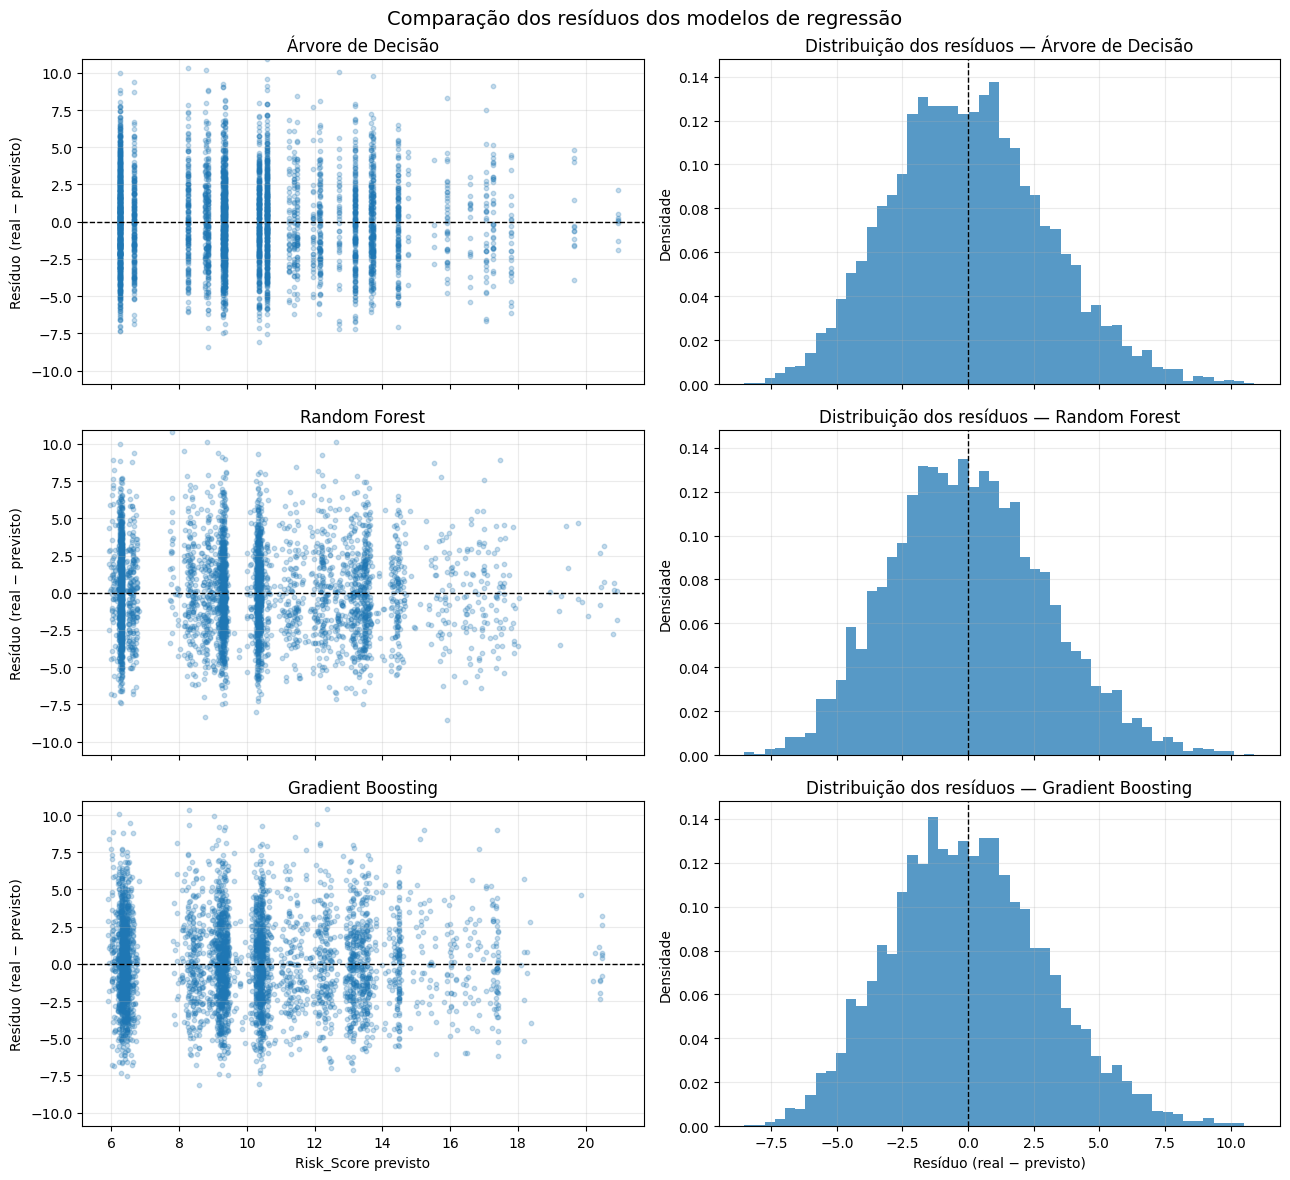

COMPARAÇÃO DOS RESÍDUOS


,Modelo,Resíduo médio,Mediana do resíduo,Desvio padrão,Percentil 95 erro absoluto
0,Árvore de Decisão,0.0180,-0.0996,2.9710,5.7720
1,Random Forest,0.0225,-0.1132,2.9531,5.7129
2,Gradient Boosting,0.0243,-0.1022,2.9528,5.7436



Gráfico e tabela salvos com sucesso!


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

nomes_modelos = list(modelos_regressao.keys())

# Mesma escala para os três gráficos de resíduos
todos_residuos = np.concatenate([
    residuos_regressao[nome]
    for nome in nomes_modelos
])

limite_residuos = np.max(np.abs(todos_residuos))
limites_histograma = np.linspace(
    todos_residuos.min(),
    todos_residuos.max(),
    51
)

fig, axes = plt.subplots(
    3, 2,
    figsize=(13, 12),
    sharex="col",
    sharey="col"
)

registros_residuos = []

for i, nome in enumerate(nomes_modelos):

    previstos = previsoes_regressao[nome]
    residuos = residuos_regressao[nome]

    assert len(residuos) == 4000
    assert np.isfinite(residuos).all()

    # Gráfico: resíduos x previsões
    axes[i, 0].scatter(
        previstos,
        residuos,
        alpha=0.25,
        s=10
    )

    axes[i, 0].axhline(
        0,
        linestyle="--",
        color="black",
        linewidth=1
    )

    axes[i, 0].set_ylim(
        -limite_residuos,
        limite_residuos
    )

    axes[i, 0].set_title(nome)
    axes[i, 0].set_ylabel("Resíduo (real − previsto)")
    axes[i, 0].grid(alpha=0.25)

    # Histograma dos resíduos
    axes[i, 1].hist(
        residuos,
        bins=limites_histograma,
        density=True,
        alpha=0.75
    )

    axes[i, 1].axvline(
        0,
        linestyle="--",
        color="black",
        linewidth=1
    )

    axes[i, 1].set_title(
        f"Distribuição dos resíduos — {nome}"
    )
    axes[i, 1].set_ylabel("Densidade")
    axes[i, 1].grid(alpha=0.25)

    registros_residuos.append({
        "Modelo": nome,
        "Resíduo médio": np.mean(residuos),
        "Mediana do resíduo": np.median(residuos),
        "Desvio padrão": np.std(residuos, ddof=1),
        "Percentil 95 erro absoluto": np.percentile(
            np.abs(residuos), 95
        )
    })

axes[-1, 0].set_xlabel("Risk_Score previsto")
axes[-1, 1].set_xlabel("Resíduo (real − previsto)")

fig.suptitle(
    "Comparação dos resíduos dos modelos de regressão",
    fontsize=14
)

fig.tight_layout()

fig.savefig(
    pasta_figuras / "comparacao_residuos_validada.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# Tabela-resumo
tabela_residuos_comparacao = pd.DataFrame(
    registros_residuos
)

tabela_residuos_comparacao.to_csv(
    pasta_tabelas / "comparacao_residuos.csv",
    index=False,
    float_format="%.16g"
)

print("COMPARAÇÃO DOS RESÍDUOS")

display(
    tabela_residuos_comparacao.round(4)
)

print("\nGráfico e tabela salvos com sucesso!")

### 7.1 Interpretação comparativa dos resíduos

Os três modelos apresentaram resíduos médios próximos de zero, variando entre 0,0180 e 0,0243, sem tendência média expressiva de superestimação ou subestimação de Risk_Score.

A Random Forest e o Gradient Boosting apresentaram desvios padrão ligeiramente menores que a Árvore de Decisão, aproximadamente 2,95 contra 2,97. Esses resultados são coerentes com as pequenas melhorias observadas nas métricas de regressão.

Nos gráficos de dispersão, a Árvore de Decisão apresenta faixas verticais mais evidentes, consequência do número limitado de previsões distintas produzidas por suas folhas. Os ensembles apresentam valores previstos mais variados.

Os histogramas são unimodais e centrados próximo de zero, com leve assimetria à direita: a cauda positiva alcança cerca de +10, enquanto a negativa chega a aproximadamente −8,5, e a média dos resíduos (cerca de +0,02) é ligeiramente superior à mediana (cerca de −0,10). Esse formato é coerente com a razão RMSE/MAE próxima de 1,25 observada na Seção 6.1. Nos gráficos de dispersão, observa-se ainda um limite inferior para os resíduos nas previsões mais baixas: como os valores reais de Risk_Score têm limite inferior próximo de −1,6 no treinamento, o resíduo (real − previsto) não pode ser muito negativo quando a previsão é pequena. Esses padrões não alteram as conclusões comparativas, mas indicam que os erros não são perfeitamente simétricos nem homogêneos ao longo da faixa de previsões.

O percentil 95 do erro absoluto variou de 5,7129 a 5,7720, demonstrando que uma parcela dos registros ainda apresenta erros consideráveis. As diferenças entre os modelos foram pequenas e não permitem afirmar superioridade estatística.

## 8. Síntese da avaliação dos modelos

A avaliação comparativa evidenciou diferenças entre o desempenho dos modelos de classificação e regressão.

**Na classificação**, o Sistema Especialista apresentou o maior F1-score (0,6224) e recall (0,6119), identificando a maior proporção dos registros positivos. Random Forest e Gradient Boosting alcançaram os maiores valores de ROC-AUC e Average Precision, demonstrando melhor capacidade de ordenação dos registros conforme os escores de classificação.

As matrizes de confusão evidenciaram um compromisso entre falsos positivos e falsos negativos: o Sistema Especialista apresentou menos falsos negativos, enquanto a Random Forest apresentou menos falsos positivos.

**Na regressão**, Random Forest e Gradient Boosting apresentaram resultados ligeiramente superiores aos da Árvore de Decisão. O Gradient Boosting alcançou o menor RMSE (2,9526), embora a diferença em relação à Random Forest (2,9529) tenha sido praticamente irrelevante.

A análise dos resíduos confirmou a proximidade entre os três modelos de regressão, com médias próximas de zero e dispersões semelhantes.

Os resultados demonstram que não existe um modelo universalmente superior em todas as métricas. A escolha depende do objetivo da previsão, dos tipos de erro considerados relevantes e dos recursos computacionais disponíveis.

Esta avaliação utiliza um único conjunto de teste e seis variáveis selecionadas. Os resultados não estabelecem validade clínica dos modelos.

As análises de generalização, viés, variância e eficiência computacional serão aprofundadas nos Notebooks 07 e 08.

A comparação adotou o F1-score como métrica principal de classificação, complementado pelo Recall devido à relevância dos falsos negativos em cenários hipotéticos de triagem. Na regressão, o RMSE foi definido como métrica principal, com MAE e R² como indicadores complementares. Essas escolhas mantêm coerência com os critérios de seleção dos modelos utilizados nos experimentos.